In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [5]:
# Directory locations
inpDir = '../../input'
outDir = '../output'

RANDOM_STATE = 24 # REMEMBER: to remove at the time of promotion to production
rng = np.random.default_rng(seed = RANDOM_STATE) # Set Random Seed for reproducibl

NOISE = 0.2
EPOCHS = 20001 # number of epochs
ALPHA = 0.1 # learning rate
N_SAMPLES = 1000 # number of samples to create
TEST_SIZE = 0.2

# parameters for Matplotlib
params = {'legend.fontsize': 'medium',
          'figure.figsize': (15, 6),
          'axes.labelsize': 'medium',
          'axes.titlesize': 'medium',
          'xtick.labelsize': 'medium',
          'ytick.labelsize': 'medium'
         }
CMAP=plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

In [ ]:
## helper  function
def plot_decision_boundary(model,X_tr, X_ts,y_tr,y_ts):
    fig , ax = plt.subplots()
    dm = 0.01
    margin = 10*dm
    x_min, x_max = X_tr[:, 0].min() - margin, X_tr[:, 0].max() - margin
    y_min, y_max = X_tr[:, 1].min() - margin, X_tr[:, 1].max() - margin

    xx, yy = np.meshgrid(np.arange(x_min, x_max, dm),np.arange(y_min, y_max, dm))

    XX = np.c_[xx.ravel(), yy.ravel()]
    XX = np.hstack((XX, np.ones((XX.shape[0], 1))))
    y_pred = []

    for row in XX:
        a = predict(row, wts)
        y_pred.append(a)
    
    Z = np.array(y_pred).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.6)
    
    ax.scatter(X_tr[:, 0], X_tr[:, 1], c=X_tr[:, 2],
               s=30, edgecolors='k', cmap='coolwarm')
    
    ax.scatter(X_ts[:, 0], X_ts[:, 1], c=X_ts[:, 2],
               s=30, marker='*', edgecolors='k', cmap=plt.cm.seismic)


In [6]:
def plot_decision_boundary(
        model:dict,
        X_tr: np.ndarray,
        y_tr: np.ndarray,
        X_ts: np.ndarray,
        y_ts: np.ndarray,
    ):
    """
    """
    fig, ax = plt.subplots()
    dm = 0.01
    margin = 10*dm
    xMin = min(X_tr[:, 0].min() - margin, X_ts[:, 0].min() - margin)
    xMax = max(X_tr[:, 1].max() + margin, X_ts[:, 1].max() + margin)
    yMin = min(y_tr[:, 0].min() - margin, y_ts[:, 0].min() - margin)
    yMax = max(y_tr[:, 1].max() + margin, y_ts[:, 1].max() + margin)

    xx, yy = np.meshgrid(np.arange(xMin, xMax, dm),
                         np.arange(yMin, yMax, dm))
    XX = np.c_[xx.ravel(), yy.ravel()]
    Z = fn_predict(model, XX).reshape(xx.shape)
    ax.contourf(xx,yy, Z, cmap=plt.cm.Paired, alpha = 0.6)
    ax.scatter(X_tr[:, 0], X_tr[:, 1], c = y_tr,
               s = 30, edgecolors='k', cmap=CMAP)
    ax.scatter(X_ts[:, 0], X_ts[:, 1], c = y_ts,
               s = 30, marker= '*', edgecolors='k', cmap=plt.cm.seismic)
    ax.set_xlabel('Feature 1')
    ax.ser_ylabel('Feature 2')
    ax.set_title('Decision Boundary')
    ax.legend()


In [10]:
X,y=datasets.make_moons(n_samples=N_SAMPLES,
                       shuffle=True,
                       noise=NOISE,
                       random_state=24)
X[:5],y[:5]

(array([[ 0.90633951,  0.90267624],
        [-1.11536828,  0.75579289],
        [ 1.88769158,  0.4175967 ],
        [-0.93345034, -0.02299851],
        [-0.96872877,  0.06396285]]),
 array([0, 0, 1, 0, 0]))

In [18]:
data_df = pd.DataFrame(X, columns = ['A','B'])
data_df['target'] = y
data_df.head()

,A,B,target
0,0.906340,0.902676,0
1,-1.115368,0.755793,0
2,1.887692,0.417597,1
3,-0.933450,-0.022999,0
4,-0.968729,0.063963,0


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=TEST_SIZE,
                                                    random_state=RANDOM_STATE,
                                                    stratify=y)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)


(800, 2) (200, 2) (800,) (200,)


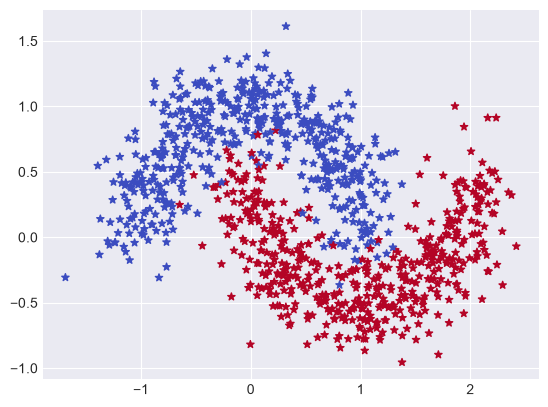

In [12]:
plt.figure()
plt.scatter(X[:,0],X[:,1],s=30,c=y,marker='*',cmap='coolwarm')

# sigmoid function

In [13]:
def fn_sigmoid(z):
    return 1/(1 + np.exp(-z))

# Tanh Activation function

In [14]:
def fn_activ(z:np.ndarray) -> np.ndarray:
    return np.tanh(z)
def fn_activ_prime(z:np.ndarray) -> np.ndarray:
    return 1.0 -np.tanh(z)**2



In [15]:
fn_activ(np.asarray([[-1, 0, -1], [-np.inf, 0, np.inf]]))


array([[-0.76159416,  0.        , -0.76159416],
       [-1.        ,  0.        ,  1.        ]])

In [33]:
def fn_predict(model: dict, X: np.ndarray):
    """
    model: Dictionary containing weights and bias
    X: input features
    """
    
    W1, W2 = model['W1'], model['W2']
    b1, b2 = model['b1'], model['b2']
    
    ### Forward propagation
    # Layer 1
    z1 = X.dot(W1) + b1 # Aggregation
    a1 = fn_activ(z1)
    #layer 2
    z2=a1.dot(W2)+b2
    a2=fn_sigmoid(z2)
    return a2>=0.5


In [30]:
def fn_calculate_loss(model: dict,X_l: np.ndarray,y_l:np.ndarray):
    """
    model: Dictionary containing weights and bias
    X: input features
    """
    m=X_l.shape[0]
    W1, W2 = model['W1'], model['W2']
    b1, b2 = model['b1'], model['b2']
    
    ### Forward propagation
    # Layer 1
    z1 = X_l.dot(W1) + b1 # Aggregation
    a1 = fn_activ(z1)
    #layer 2
    z2=a1.dot(W2)+b2
    a2=fn_sigmoid(z2)

    data_loss = -( y_l * np.log(a2) + ( 1- y_l ) * np.log( 1 - a2 ) ).sum()

    return data_loss / m


In [35]:
weights = np.array([0.1, 2.0, 1.0])

display(data_df.loc[0])
predict(data_df.loc[0].values, weights)


A         0.906340
B         0.902676
target    0.000000
Name: 0, dtype: float64

NameError: name 'X_l' is not defined

In [41]:
def fn_build_model(nn_hdim:np.ndarray,
    X: np.ndarray,
    y: np.ndarray,
    alpha: np.float64= ALPHA,
    n_epochs: np.int64= EPOCHS
    ) -> dict:
    """
    nn_hdim: number of hidden units,
    X: features,
    y: labels,
    alpha: learning rate,
    n_epochs: number of passes therough complete data for gradient descent
    """

    m, nn_input_dim = X.shape
    nn_output_dim = y.shape[1]

    W1 = rng.random((nn_input_dim, nn_hdim), dtype=np.float32) / np.sqrt(nn_input_dim)
    W2 = rng.random((nn_hdim, nn_output_dim), dtype=np.float32) / np.sqrt(nn_hdim)

    b1 = np.zeros((1, nn_hdim), dtype=np.float32)
    b2 = np.zeros((1, nn_output_dim), dtype=np.float32)
    curr_loss = 0
    loss, epoch= [], []

    for i in range(n_epochs): # loop for number of epochs
        ### Forward propagation
        # Layer 1
        z1 = X.dot(W1) + b1 # Aggregation
        a1 = fn_activ(z1) # Activation

        #Layer 2
        z2 = a1.dot(W2) + b2 # Aggregation
        a2 = fn_sigmoid(z2)

        ### Back Propagation
        #Layer 2
        dz2 = a2-y
        dW2 = (a1.T).dot(dz2)
        assert (W2.shape == dW2.shape), f'Shape- W2:{W2.shape} | dW2:{dW2.shape}'
        db2 = np.sum(dz2, axis=0, keepdims=True)
        assert (b2.shape == db2.shape), f'Shape- b2:{b2.shape} | db2:{db2.shape}'
        da1 = dz2.dot(a2.T)
        assert (a1.shape == da1.shape), f'Shape- a1:{a1.shape} | da1:{da1.shape}'
        # Layer 1
        dz1= da1*fn_activ_prime(z1)
        dW1 = (X.T).dot(dz1)
        assert (W1.shape == dW2.shape), f'Shape- W1:{W1.shape} | dW1:{dW1.shape}'
        db1 = np.sum(dz1, axis=0, keepdims=True)
        assert (b1.shape == db1.shape), f'Shape- b1:{b1.shape} | db1:{db1.shape}'

        W1 = W1 - alpha * dW1 / m
        W2 = W2 - alpha * dW2 / m
        b1 = b1 - alpha * db1 / m
        b2 = b2 - alpha * db2 / m

        model = {"W1": W1, "W2": W2, "b1": b1, "b2": b2}

        if i % 100 == 0:
            curr_loss = fn_calculate_loss(model=model, X_l=X, y_l=y)
            loss.append(curr_loss)
            epoch.append(i)
            print(f"Epoch {i:3d}: Loss = {curr_loss:.4f}")
    loss_hist['epoch'] = epoch
    loss_hist['loss'] = loss

    return model

